In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

from google.colab import files

uploaded = files.upload()

image_path = list(uploaded.keys())[0]

print("Selected image:", image_path)

Saving salt and pepper.jpeg to salt and pepper (1).jpeg
Selected image: salt and pepper (1).jpeg


In [ ]:
# Load image in grayscale mode
img = cv2.imread(image_path, 0)

if img is None:
    print("Error: Image could not be loaded.")
else:
    print("Image loaded successfully")
    print("Image shape:", img.shape)

Image loaded successfully
Image shape: (508, 393)


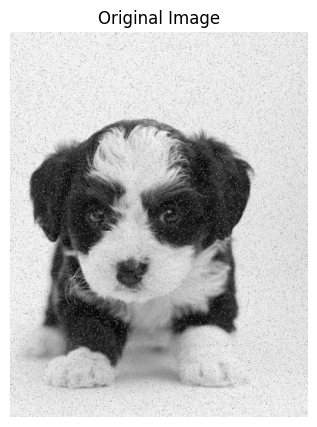

In [ ]:
plt.figure(figsize=(6, 5))

plt.imshow(img, cmap='gray')

plt.title("Original Image")

plt.axis("off")

plt.show()

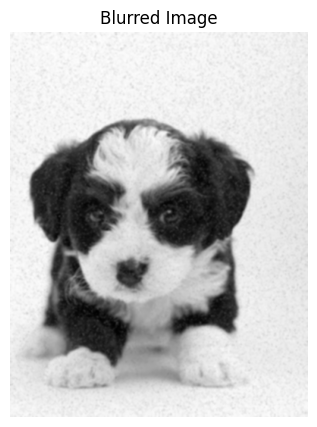

In [ ]:
blur = cv2.GaussianBlur(
    img,
    (5, 5),
    0
)

plt.figure(figsize=(6, 5))

plt.imshow(
    blur,
    cmap='gray'
)

plt.title("Blurred Image")

plt.axis("off")

plt.show()

In [ ]:
img_float = img.astype(np.float32)

blur_float = blur.astype(np.float32)

In [ ]:
mask = img_float - blur_float

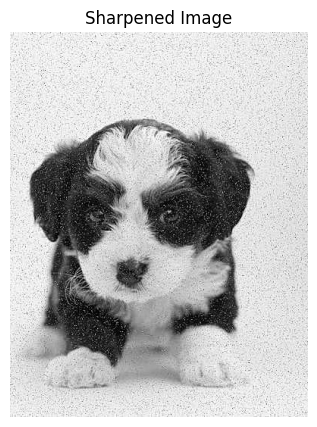

In [ ]:
sharpened = img_float + mask

# Keep pixel values between 0 and 255
sharpened = np.clip(
    sharpened,
    0,
    255
).astype(np.uint8)

plt.figure(figsize=(6, 5))

plt.imshow(
    sharpened,
    cmap='gray'
)

plt.title("Sharpened Image")

plt.axis("off")

plt.show()

In [ ]:
A = 2

high_boost = (
    (A - 1) * img_float
    +
    sharpened.astype(np.float32)
)

# Keep values between 0 and 255
high_boost = np.clip(
    high_boost,
    0,
    255
).astype(np.uint8)

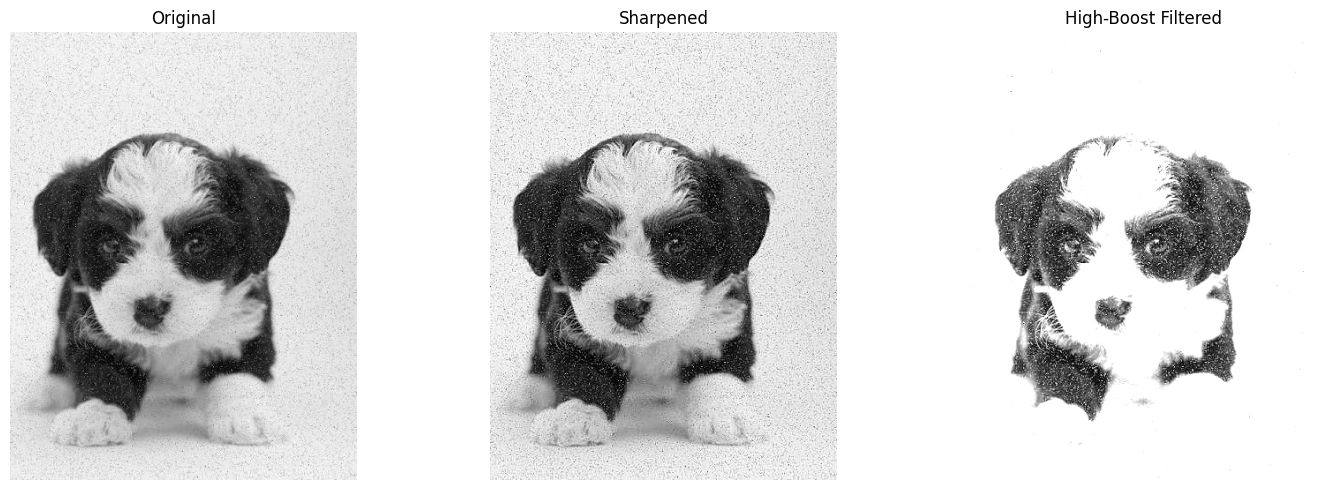

In [ ]:
plt.figure(figsize=(15, 5))


# Original Image
plt.subplot(1, 3, 1)

plt.imshow(
    img,
    cmap='gray'
)

plt.title("Original")

plt.axis("off")


# Sharpened Image
plt.subplot(1, 3, 2)

plt.imshow(
    sharpened,
    cmap='gray'
)

plt.title("Sharpened")

plt.axis("off")


# High-Boost Filtered Image
plt.subplot(1, 3, 3)

plt.imshow(
    high_boost,
    cmap='gray'
)

plt.title("High-Boost Filtered")

plt.axis("off")


plt.tight_layout()

plt.show()

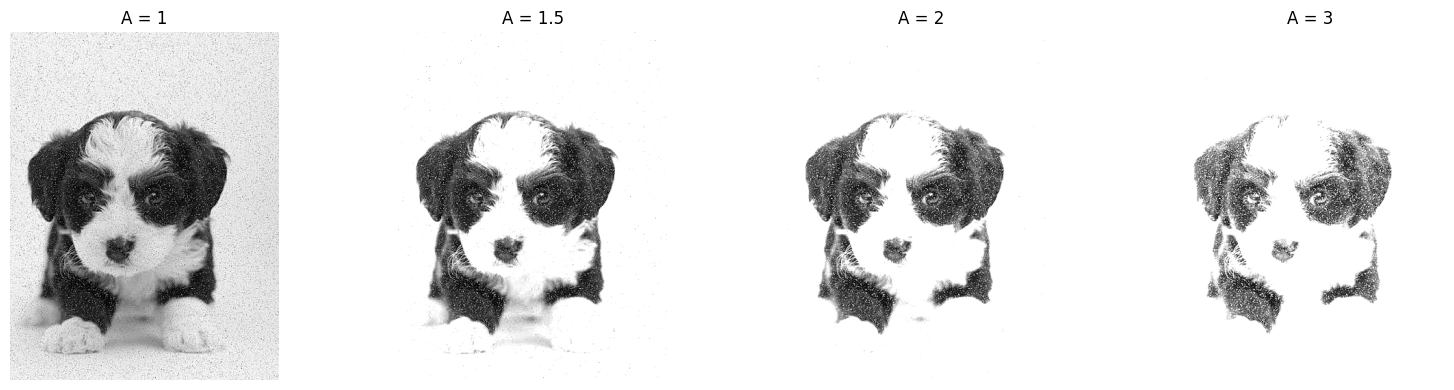

In [ ]:
A_values = [
    1,
    1.5,
    2,
    3
]


plt.figure(figsize=(16, 4))


for i, A in enumerate(A_values):

    high_boost = (
        (A - 1) * img_float
        +
        sharpened.astype(np.float32)
    )

    high_boost = np.clip(
        high_boost,
        0,
        255
    ).astype(np.uint8)


    plt.subplot(
        1,
        4,
        i + 1
    )


    plt.imshow(
        high_boost,
        cmap='gray'
    )


    plt.title(
        f"A = {A}"
    )


    plt.axis("off")


plt.tight_layout()

plt.show()

In [ ]:
gamma_dark = 0.5

gamma_bright = 1.5


# Calculate average image intensity
threshold = np.mean(img)


print("Threshold:", threshold)

Threshold: 183.32167758610328


In [ ]:
# Pixels below the threshold
dark_mask = img < threshold


# Pixels greater than or equal to the threshold
bright_mask = img >= threshold


print(
    "Dark pixels:",
    np.sum(dark_mask)
)


print(
    "Bright pixels:",
    np.sum(bright_mask)
)

Dark pixels: 61042
Bright pixels: 138602


In [ ]:
img_normalized = (
    img.astype(np.float32)
    /
    255.0
)

In [ ]:
# Gamma correction for dark regions
dark_corrected = (
    255
    *
    (
        img_normalized
        **
        gamma_dark
    )
)


# Gamma correction for bright regions
bright_corrected = (
    255
    *
    (
        img_normalized
        **
        gamma_bright
    )
)

In [ ]:
adaptive_output = np.zeros_like(
    img_normalized
)


# Apply gamma correction to dark pixels
adaptive_output[
    dark_mask
] = dark_corrected[
    dark_mask
]


# Apply gamma correction to bright pixels
adaptive_output[
    bright_mask
] = bright_corrected[
    bright_mask
]


# Convert back to uint8
adaptive_output = np.clip(
    adaptive_output,
    0,
    255
).astype(np.uint8)

In [ ]:
# Create empty images
dark_region = np.zeros_like(img)

bright_region = np.zeros_like(img)


# Keep only dark pixels
dark_region[
    dark_mask
] = img[
    dark_mask
]


# Keep only bright pixels
bright_region[
    bright_mask
] = img[
    bright_mask
]

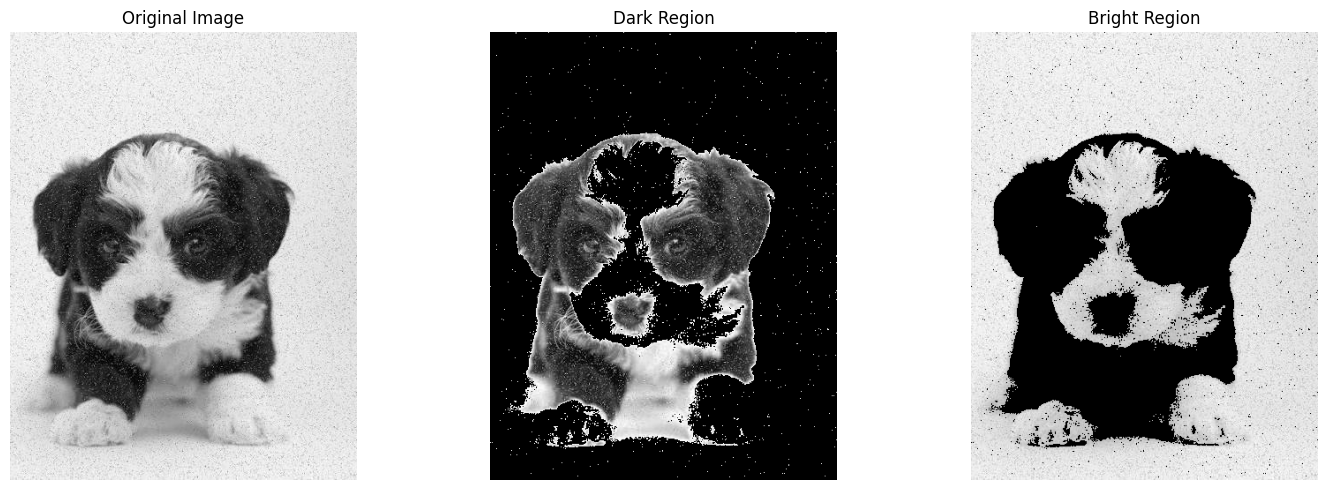

In [ ]:
plt.figure(figsize=(15, 5))


# Original
plt.subplot(1, 3, 1)

plt.imshow(
    img,
    cmap='gray'
)

plt.title("Original Image")

plt.axis("off")


# Dark Region
plt.subplot(1, 3, 2)

plt.imshow(
    dark_region,
    cmap='gray'
)

plt.title("Dark Region")

plt.axis("off")


# Bright Region
plt.subplot(1, 3, 3)

plt.imshow(
    bright_region,
    cmap='gray'
)

plt.title("Bright Region")

plt.axis("off")


plt.tight_layout()

plt.show()

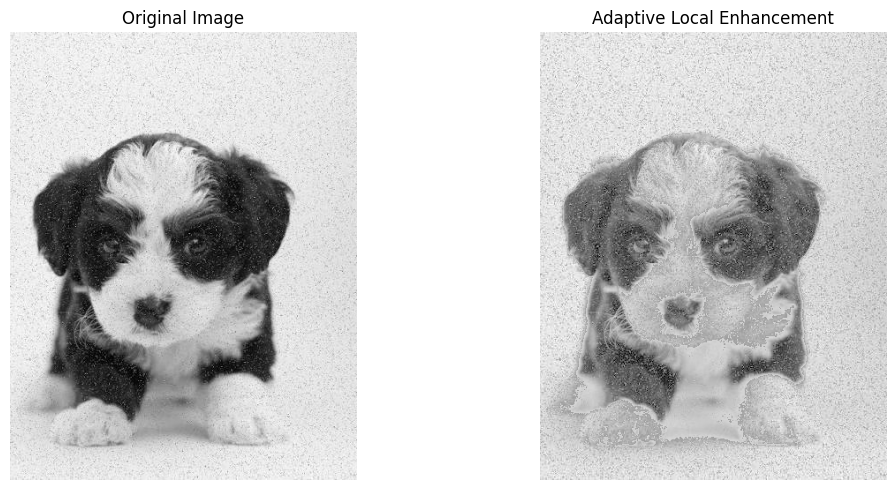

In [ ]:
plt.figure(figsize=(12, 5))


# Original Image
plt.subplot(1, 2, 1)

plt.imshow(
    img,
    cmap='gray'
)

plt.title("Original Image")

plt.axis("off")


# Adaptive Enhancement
plt.subplot(1, 2, 2)

plt.imshow(
    adaptive_output,
    cmap='gray'
)

plt.title("Adaptive Local Enhancement")

plt.axis("off")


plt.tight_layout()

plt.show()

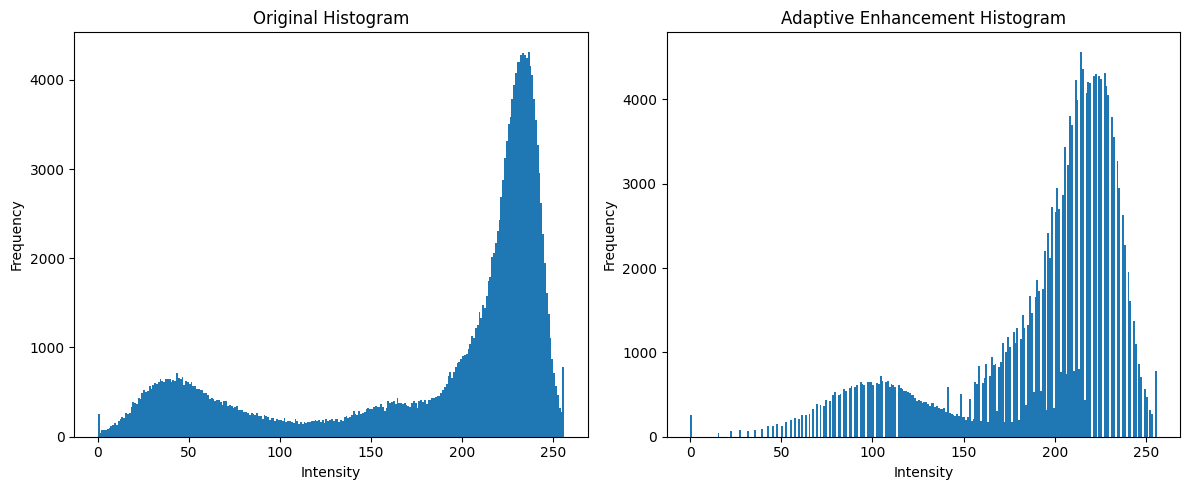

In [ ]:
plt.figure(figsize=(12, 5))


# Original Histogram
plt.subplot(1, 2, 1)

plt.hist(
    img.ravel(),
    bins=256,
    range=[0, 256]
)

plt.title("Original Histogram")

plt.xlabel("Intensity")

plt.ylabel("Frequency")


# Adaptive Enhancement Histogram
plt.subplot(1, 2, 2)

plt.hist(
    adaptive_output.ravel(),
    bins=256,
    range=[0, 256]
)

plt.title("Adaptive Enhancement Histogram")

plt.xlabel("Intensity")

plt.ylabel("Frequency")


plt.tight_layout()

plt.show()